# Estimating average effects under random assignment

The average treatment effect compares the two potential outcomes for the same population:

$$
\tau_{\mathrm{ATE}}
=\mathbb E\!\left[Y(1)-Y(0)\right]
=\mathbb E[Y(1)]-\mathbb E[Y(0)].
$$

Here, $Y(1)$ is the outcome under treatment, $Y(0)$ is the outcome under control, $\tau_{\mathrm{ATE}}$ is their population average difference, and $\mathbb E$ denotes a population mean.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered




### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd



## Display float

In [ ]:
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.causal_factor_analysis import CausalDAG, DifferenceInDifferencesEstimate, StructuralCausalModelResult, TreatmentEffectDecomposition, average_treatment_effect, backdoor_adjusted_average_treatment_effect, backdoor_adjusted_expectation, difference_in_differences, evaluate_structural_causal_model, frontdoor_adjusted_probability, linear_instrumental_variable_effect, randomized_mean_difference, treatment_effect_decomposition

FIGURES = ROOT / "outputs" / "figures" / "03_structural_treatment_effects"
TABLES = ROOT / "outputs" / "tables" / "03_structural_treatment_effects"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float);



## Table display and number formatting

In [ ]:
def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Ols coefficient

In [ ]:
def ols_coefficient(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        values = np.asarray(controls, dtype=float)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        columns.extend(values[:, index] for index in range(values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_dag(axis, dag, positions, title):
    graph = nx.DiGraph(dag.directed_edges)
    graph.add_nodes_from(dag.nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=palette["cyan"], node_size=1800, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()



## Exact and generated average-effect calculations

In [1]:
quickstart_effect = average_treatment_effect(3.5, 1.25)
rng = np.random.default_rng(250101)
n_population = 20000
covariate = rng.normal(size=n_population)
control_shock = rng.normal(scale=0.8, size=n_population)
control_potential = 1.0 + 0.7 * covariate + control_shock
individual_effect = 0.8 + 0.25 * covariate
treated_potential = control_potential + individual_effect
true_ate = average_treatment_effect(treated_potential.mean(), control_potential.mean())
potential_summary = pd.DataFrame([
    {"Quantity": "Quickstart treated mean", "Value": 3.5},
    {"Quantity": "Quickstart control mean", "Value": 1.25},
    {"Quantity": "Quickstart average effect", "Value": quickstart_effect},
    {"Quantity": "Generated population average effect", "Value": true_ate},
    {"Quantity": "Smallest individual effect", "Value": individual_effect.min()},
    {"Quantity": "Largest individual effect", "Value": individual_effect.max()},
])
potential_moments = pd.DataFrame([
    {"Potential outcome": "Control Y(0)", "Mean": control_potential.mean(), "Standard deviation": control_potential.std(ddof=1)},
    {"Potential outcome": "Treated Y(1)", "Mean": treated_potential.mean(), "Standard deviation": treated_potential.std(ddof=1)},
    {"Potential outcome": "Individual effect", "Mean": individual_effect.mean(), "Standard deviation": individual_effect.std(ddof=1)},
])
save_table(potential_summary, "average_effect_quickstart", "Exact and generated average-effect calculations.", "tab:chapter25-average-effect-quickstart")
save_table(potential_moments, "potential_outcome_moments", "Moments of the generated potential outcomes and individual effects.", "tab:chapter25-potential-outcome-moments")
display(potential_summary)
display(potential_moments);



,Quantity,Value
0,Quickstart treated mean,3.5
1,Quickstart control mean,1.25
2,Quickstart average effect,2.25
3,Generated population average effect,0.799919
4,Smallest individual effect,-0.136696
5,Largest individual effect,1.745574


,Potential outcome,Mean,Standard deviation
0,Control Y(0),0.998375,1.056768
1,Treated Y(1),1.798295,1.23346
2,Individual effect,0.799919,0.24828


## Paired potential outcomes

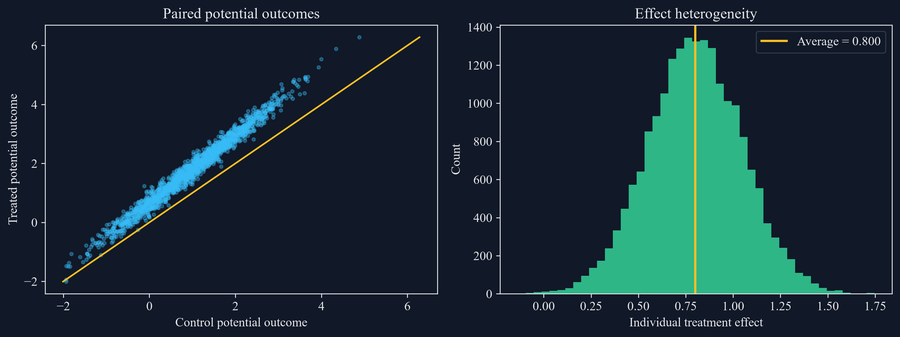

In [1]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
draw_index = np.linspace(0, n_population - 1, 1600, dtype=int)
axes[0].scatter(control_potential[draw_index], treated_potential[draw_index], s=9, alpha=0.35, color=palette["cyan"])
limits = [min(control_potential[draw_index].min(), treated_potential[draw_index].min()), max(control_potential[draw_index].max(), treated_potential[draw_index].max())]
axes[0].plot(limits, limits, color=palette["amber"], linewidth=1.5)
axes[0].set_xlabel("Control potential outcome")
axes[0].set_ylabel("Treated potential outcome")
axes[0].set_title("Paired potential outcomes")
axes[1].hist(individual_effect, bins=45, color=palette["green"], alpha=0.85)
axes[1].axvline(true_ate, color=palette["amber"], linewidth=2, label=f"Average = {true_ate:.3f}")
axes[1].set_xlabel("Individual treatment effect")
axes[1].set_ylabel("Count")
axes[1].set_title("Effect heterogeneity")
axes[1].legend()
figure.tight_layout()
save_figure(figure, "potential_outcomes_and_effects")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Recovering the effect by random assignment

Under random assignment, the sample contrast is:

$$
\widehat\tau_{\mathrm{DM}}
=\overline Y_{T=1}-\overline Y_{T=0}.
$$

Here, $T$ is the treatment indicator, $\overline Y_{T=1}$ is the mean observed outcome among treated units, $\overline Y_{T=0}$ is the mean observed outcome among control units, and $\widehat\tau_{\mathrm{DM}}$ is the difference-in-means estimate.

### Random and covariate-selected treatment assignments

In [2]:
random_assignment = rng.binomial(1, 0.5, n_population)
selected_probability = 1.0 / (1.0 + np.exp(-(-0.2 + 1.1 * covariate)))
selected_assignment = rng.binomial(1, selected_probability)
observed_random = random_assignment * treated_potential + (1 - random_assignment) * control_potential
observed_selected = selected_assignment * treated_potential + (1 - selected_assignment) * control_potential
randomized_estimate = randomized_mean_difference(observed_random[random_assignment == 1], observed_random[random_assignment == 0])
selected_estimate = randomized_mean_difference(observed_selected[selected_assignment == 1], observed_selected[selected_assignment == 0])
assignment_comparison = pd.DataFrame([
    {"Assignment": "Random", "Treated share": random_assignment.mean(), "Mean covariate among treated": covariate[random_assignment == 1].mean(), "Mean covariate among controls": covariate[random_assignment == 0].mean(), "Observed difference": randomized_estimate, "Error from population ATE": randomized_estimate - true_ate},
    {"Assignment": "Selected by covariate", "Treated share": selected_assignment.mean(), "Mean covariate among treated": covariate[selected_assignment == 1].mean(), "Mean covariate among controls": covariate[selected_assignment == 0].mean(), "Observed difference": selected_estimate, "Error from population ATE": selected_estimate - true_ate},
])
save_table(assignment_comparison, "assignment_comparison", "Random and covariate-selected treatment assignments.", "tab:chapter25-assignment-comparison")
display(assignment_comparison);



,Assignment,Treated share,Mean covariate among treated,Mean covariate among controls,Observed difference,Error from population ATE
0,Random,0.49725,0.006255,-0.006828,0.806651,0.006731
1,Selected by covariate,0.4622,0.470496,-0.404956,1.527637,0.727718


### Repeated randomized differences in means

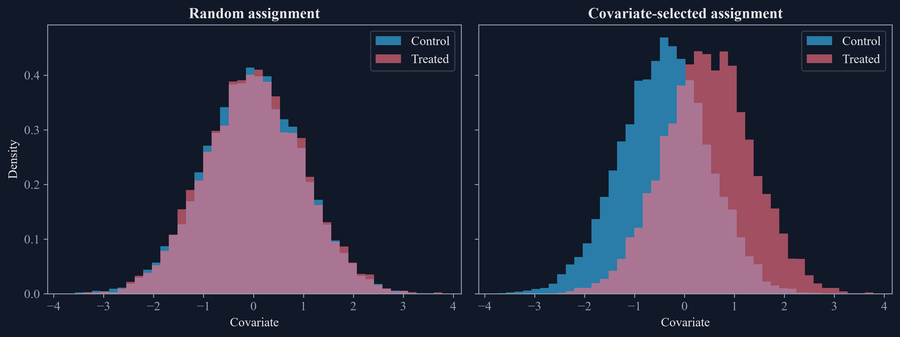

,Repetitions,Sample size,Mean estimate,Bias,Standard deviation,Root mean squared error,Middle 95 percent lower,Middle 95 percent upper
0,500,600,0.803566,0.003646,0.094759,0.094735,0.620168,0.98735


In [2]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
bins = np.linspace(covariate.min(), covariate.max(), 45)
for axis, treatment, title in [(axes[0], random_assignment, "Random assignment"), (axes[1], selected_assignment, "Covariate-selected assignment")]:
    axis.hist(covariate[treatment == 0], bins=bins, density=True, alpha=0.62, color=palette["cyan"], label="Control")
    axis.hist(covariate[treatment == 1], bins=bins, density=True, alpha=0.62, color=palette["rose"], label="Treated")
    axis.set_xlabel("Covariate")
    axis.set_title(title)
    axis.legend()
axes[0].set_ylabel("Density")
figure.tight_layout()
save_figure(figure, "assignment_covariate_balance")

repetitions = 500
repetition_estimates = []
for repetition in range(repetitions):
    sample_rng = np.random.default_rng(251000 + repetition)
    indices = sample_rng.integers(0, n_population, 600)
    assignment = sample_rng.binomial(1, 0.5, len(indices))
    outcomes = assignment * treated_potential[indices] + (1 - assignment) * control_potential[indices]
    repetition_estimates.append(randomized_mean_difference(outcomes[assignment == 1], outcomes[assignment == 0]))
repetition_estimates = np.asarray(repetition_estimates)
randomized_repetition_summary = pd.DataFrame([{
    "Repetitions": repetitions,
    "Sample size": 600,
    "Mean estimate": repetition_estimates.mean(),
    "Bias": repetition_estimates.mean() - true_ate,
    "Standard deviation": repetition_estimates.std(ddof=1),
    "Root mean squared error": np.sqrt(np.mean((repetition_estimates - true_ate) ** 2)),
    "Middle 95 percent lower": np.quantile(repetition_estimates, 0.025),
    "Middle 95 percent upper": np.quantile(repetition_estimates, 0.975),
}])
save_table(randomized_repetition_summary, "randomized_repetition_summary", "Repeated randomized differences in means.", "tab:chapter25-randomized-repetition")
display(randomized_repetition_summary);



### Sampling variation under random assignment

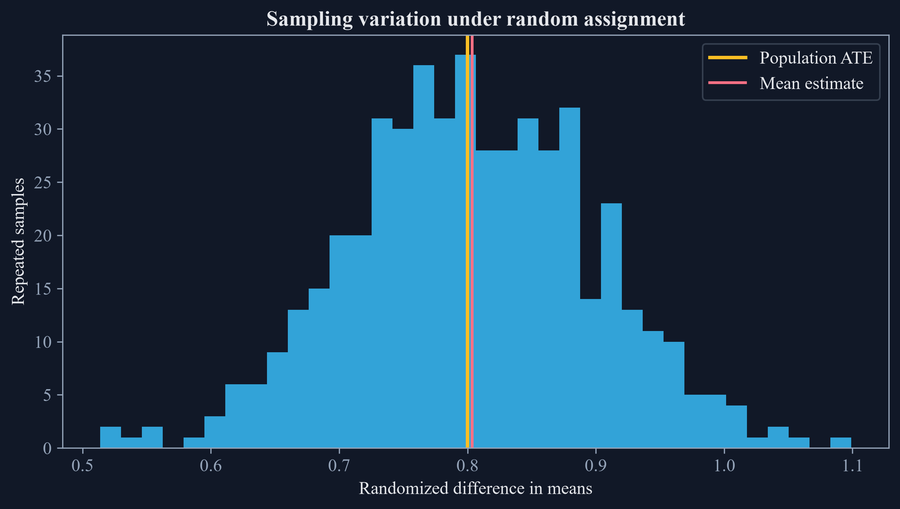

In [2]:
figure, axis = plt.subplots(figsize=(8.2, 4.7))
axis.hist(repetition_estimates, bins=36, color=palette["cyan"], alpha=0.85)
axis.axvline(true_ate, color=palette["amber"], linewidth=2.2, label="Population ATE")
axis.axvline(repetition_estimates.mean(), color=palette["rose"], linewidth=1.8, label="Mean estimate")
axis.set_xlabel("Randomized difference in means")
axis.set_ylabel("Repeated samples")
axis.set_title("Sampling variation under random assignment")
axis.legend()
figure.tight_layout()
save_figure(figure, "randomized_estimate_distribution")

## Precision as sample size grows

Repeated-sample bias and root mean squared error are measured by:

$$
\widehat B_R=\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau),
\qquad
\widehat{\operatorname{RMSE}}_R
=\sqrt{\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau)^2}.
$$

Here, $R$ is the number of repeated samples, $r$ labels one sample, $\widehat\tau_r$ is its estimated effect, $\tau$ is the known population effect, $\widehat B_R$ is estimated bias, and $\widehat{\operatorname{RMSE}}_R$ is estimated root mean squared error.

,Sample size,Mean estimate,Bias,Standard deviation,Root mean squared error
0,50,0.816066,0.016147,0.31797,0.317926
1,100,0.80402,0.0041,0.233831,0.233532
2,250,0.820442,0.020523,0.153787,0.154932
3,500,0.796342,-0.003578,0.104062,0.103975
4,1000,0.801753,0.001833,0.07387,0.073787
5,2500,0.799194,-0.000725,0.045115,0.045057


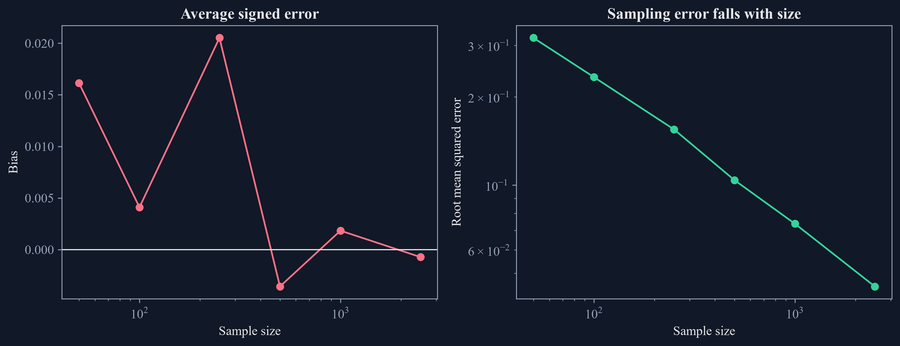

In [3]:
sample_sizes = [50, 100, 250, 500, 1000, 2500]
size_rows = []
for sample_size in sample_sizes:
    estimates = []
    for repetition in range(350):
        sample_rng = np.random.default_rng(252000 + 1000 * sample_size + repetition)
        indices = sample_rng.integers(0, n_population, sample_size)
        assignment = sample_rng.binomial(1, 0.5, sample_size)
        outcomes = assignment * treated_potential[indices] + (1 - assignment) * control_potential[indices]
        estimates.append(randomized_mean_difference(outcomes[assignment == 1], outcomes[assignment == 0]))
    estimates = np.asarray(estimates)
    size_rows.append({"Sample size": sample_size, "Mean estimate": estimates.mean(), "Bias": estimates.mean() - true_ate, "Standard deviation": estimates.std(ddof=1), "Root mean squared error": np.sqrt(np.mean((estimates - true_ate) ** 2))})
randomized_sample_size = pd.DataFrame(size_rows)
save_table(randomized_sample_size, "randomized_sample_size", "Randomized-estimator behavior as sample size grows.", "tab:chapter25-randomized-sample-size")
display(randomized_sample_size)

figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
axes[0].plot(randomized_sample_size["Sample size"], randomized_sample_size["Bias"], marker="o", color=palette["rose"])
axes[0].axhline(0, color=palette["text"], linewidth=1)
axes[0].set_xscale("log")
axes[0].set_xlabel("Sample size")
axes[0].set_ylabel("Bias")
axes[0].set_title("Average signed error")
axes[1].plot(randomized_sample_size["Sample size"], randomized_sample_size["Root mean squared error"], marker="o", color=palette["green"])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Sample size")
axes[1].set_ylabel("Root mean squared error")
axes[1].set_title("Sampling error falls with size")
figure.tight_layout()
save_figure(figure, "randomized_sample_size_behavior")

## How selection enters the observed difference

The treated-versus-control difference can be separated as follows:

$$
\mathbb E[Y\mid T=1]-\mathbb E[Y\mid T=0]
=\mathbb E[Y(1)-Y(0)\mid T=1]
+\left\{\mathbb E[Y(0)\mid T=1]-\mathbb E[Y(0)\mid T=0]\right\}.
$$

Here, $T$ is treatment status, the first term on the right is the average treatment effect among treated units, the bracketed term is selection bias in the untreated potential outcome, and consistency connects the observed treated outcome to $Y(1)$ for treated units.

,Component,Value
0,Observed difference,1.527637
1,Effect among treated,0.917624
2,Selection bias,0.610013
3,Sum of effect and selection,1.527637


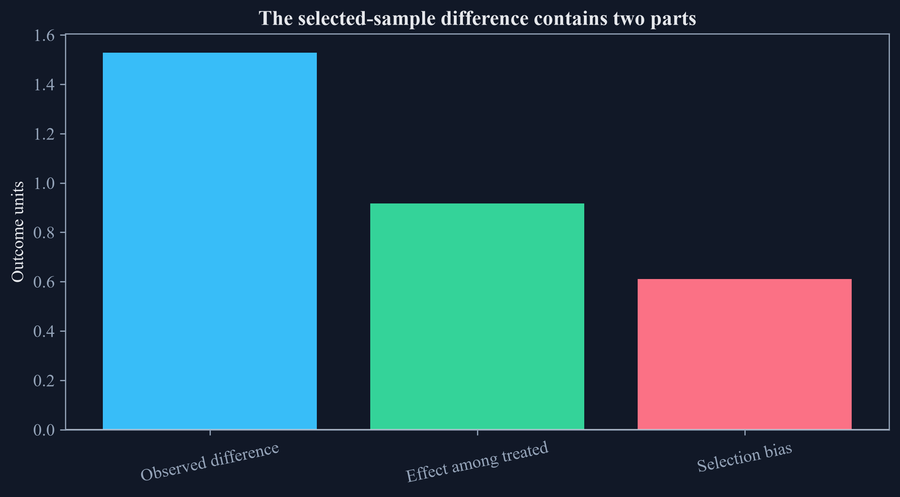

In [4]:
observed_treated_mean = observed_selected[selected_assignment == 1].mean()
observed_control_mean = observed_selected[selected_assignment == 0].mean()
counterfactual_control_treated = control_potential[selected_assignment == 1].mean()
decomposition = treatment_effect_decomposition(observed_treated_mean, observed_control_mean, counterfactual_control_treated)
decomposition_table = pd.DataFrame([
    {"Component": "Observed difference", "Value": decomposition.observed_difference},
    {"Component": "Effect among treated", "Value": decomposition.average_treatment_effect_on_treated},
    {"Component": "Selection bias", "Value": decomposition.sample_selection_bias},
    {"Component": "Sum of effect and selection", "Value": decomposition.average_treatment_effect_on_treated + decomposition.sample_selection_bias},
])
save_table(decomposition_table, "selection_decomposition", "Observed difference separated into effect among treated and selection bias.", "tab:chapter25-selection-decomposition")
display(decomposition_table)

figure, axis = plt.subplots(figsize=(8.4, 4.7))
labels = decomposition_table["Component"].iloc[:3]
values = decomposition_table["Value"].iloc[:3]
axis.bar(labels, values, color=[palette["cyan"], palette["green"], palette["rose"]])
axis.axhline(0, color=palette["text"], linewidth=1)
axis.set_ylabel("Outcome units")
axis.set_title("The selected-sample difference contains two parts")
axis.tick_params(axis="x", rotation=12)
figure.tight_layout()
save_figure(figure, "selection_decomposition")

## Adjustment by standardization

A standardized effect averages within-group contrasts over a common adjustment distribution:

$$
\tau_{\mathrm{adj}}
=\sum_{s}\left\{\mathbb E[Y\mid T=1,S=s]-\mathbb E[Y\mid T=0,S=s]\right\}P(S=s).
$$

Here, $S$ is a valid adjustment variable, $s$ labels one of its groups, $P(S=s)$ is that group's population share, and $\tau_{\mathrm{adj}}$ is the standardized average contrast.

### Inputs to the ten-group standardization calculation

In [5]:
strata = pd.qcut(covariate, 10, labels=False, duplicates="drop")
stratum_rows = []
treated_means = []
control_means = []
weights = []
for stratum in sorted(np.unique(strata)):
    member = strata == stratum
    treated_member = member & (selected_assignment == 1)
    control_member = member & (selected_assignment == 0)
    treated_mean = observed_selected[treated_member].mean()
    control_mean = observed_selected[control_member].mean()
    weight = member.mean()
    treated_means.append(treated_mean)
    control_means.append(control_mean)
    weights.append(weight)
    stratum_rows.append({"Stratum": int(stratum) + 1, "Population share": weight, "Treated count": treated_member.sum(), "Control count": control_member.sum(), "Treated mean": treated_mean, "Control mean": control_mean, "Within-stratum contrast": treated_mean - control_mean})
standardization_inputs = pd.DataFrame(stratum_rows)
adjusted_effect = backdoor_adjusted_average_treatment_effect(treated_means, control_means, weights)
standardized_treated = backdoor_adjusted_expectation(treated_means, weights)
standardized_control = backdoor_adjusted_expectation(control_means, weights)
hand_expectation = backdoor_adjusted_expectation((0.1, 0.8), (0.75, 0.25))
hand_effect = backdoor_adjusted_average_treatment_effect((0.4, 0.9), (0.1, 0.2), (0.75, 0.25))
adjustment_comparison = pd.DataFrame([
    {"Quantity": "Population ATE", "Value": true_ate},
    {"Quantity": "Selected observed difference", "Value": selected_estimate},
    {"Quantity": "Ten-stratum adjusted effect", "Value": adjusted_effect},
    {"Quantity": "Standardized treated mean", "Value": standardized_treated},
    {"Quantity": "Standardized control mean", "Value": standardized_control},
    {"Quantity": "Two-stratum expectation check", "Value": hand_expectation},
    {"Quantity": "Two-stratum effect check", "Value": hand_effect},
])
save_table(standardization_inputs, "standardization_inputs", "Inputs to the ten-group standardization calculation.", "tab:chapter25-standardization-inputs")
save_table(adjustment_comparison, "adjustment_comparison", "Observed, adjusted, and known treatment-effect quantities.", "tab:chapter25-adjustment-comparison")
display(standardization_inputs)
display(adjustment_comparison);



,Stratum,Population share,Treated count,Control count,Treated mean,Control mean,Within-stratum contrast
0,1,0.1,231,1769,0.256914,-0.236618,0.493532
1,2,0.1,416,1584,0.858465,0.266037,0.592428
2,3,0.1,583,1417,1.144812,0.549928,0.594885
3,4,0.1,713,1287,1.444518,0.713709,0.730809
4,5,0.1,796,1204,1.679681,0.9559,0.72378
5,6,0.1,978,1022,1.885299,1.023924,0.861375
6,7,0.1,1112,888,2.218437,1.301601,0.916836
7,8,0.1,1285,715,2.470819,1.440786,1.030033
8,9,0.1,1432,568,2.750718,1.738431,1.012287
9,10,0.1,1698,302,3.456134,2.101028,1.355107


,Quantity,Value
0,Population ATE,0.799919
1,Selected observed difference,1.527637
2,Ten-stratum adjusted effect,0.831107
3,Standardized treated mean,1.81658
4,Standardized control mean,0.985472
5,Two-stratum expectation check,0.275
6,Two-stratum effect check,0.4


### Overlap inside adjustment groups

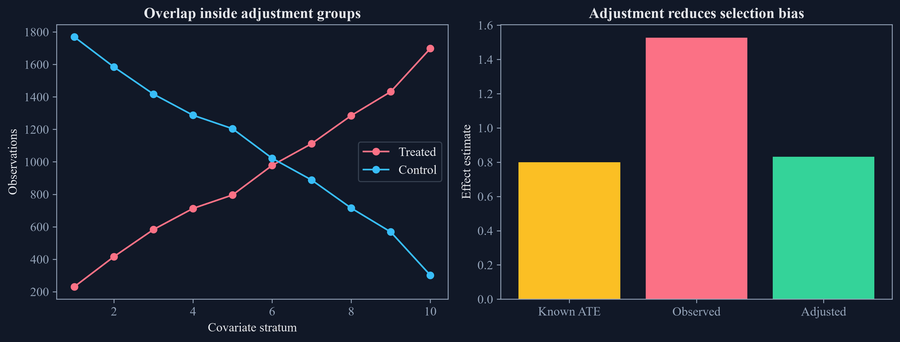

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11.6, 4.5))
axes[0].plot(standardization_inputs["Stratum"], standardization_inputs["Treated count"], marker="o", color=palette["rose"], label="Treated")
axes[0].plot(standardization_inputs["Stratum"], standardization_inputs["Control count"], marker="o", color=palette["cyan"], label="Control")
axes[0].set_xlabel("Covariate stratum")
axes[0].set_ylabel("Observations")
axes[0].set_title("Overlap inside adjustment groups")
axes[0].legend()
comparison_labels = ["Known ATE", "Observed", "Adjusted"]
comparison_values = [true_ate, selected_estimate, adjusted_effect]
axes[1].bar(comparison_labels, comparison_values, color=[palette["amber"], palette["rose"], palette["green"]])
axes[1].set_ylabel("Effect estimate")
axes[1].set_title("Adjustment reduces selection bias")
figure.tight_layout()
save_figure(figure, "standardization_overlap_and_effect")

## A discrete front-door calculation

The discrete front-door formula used by the public calculation is:

$$
P(y\mid\operatorname{do}(x))
=\sum_m P(m\mid x)\sum_{x'}P(y\mid m,x')P(x').
$$

Here, $x$ is the treatment value set by intervention, $m$ indexes mediator states, $x'$ indexes observed treatment states, $P(m\mid x)$ gives the mediator distribution under the chosen treatment, and $P(y\mid m,x')$ gives the conditional chance of one fixed outcome event.

In [6]:
mediator_probabilities = (0.25, 0.75)
outcome_probabilities = ((0.1, 0.5), (0.4, 0.8))
treatment_probabilities = (0.6, 0.4)
frontdoor_probability = frontdoor_adjusted_probability(mediator_probabilities, outcome_probabilities, treatment_probabilities)
inner_values = np.asarray(outcome_probabilities) @ np.asarray(treatment_probabilities)
frontdoor_hand = pd.DataFrame([
    {"Mediator state": 0, "Mediator weight": mediator_probabilities[0], "Inner outcome average": inner_values[0], "Contribution": mediator_probabilities[0] * inner_values[0]},
    {"Mediator state": 1, "Mediator weight": mediator_probabilities[1], "Inner outcome average": inner_values[1], "Contribution": mediator_probabilities[1] * inner_values[1]},
])
frontdoor_total = pd.DataFrame([{"Calculation": "Sum of contributions", "Probability": frontdoor_hand["Contribution"].sum()}, {"Calculation": "Public function", "Probability": frontdoor_probability}])
save_table(frontdoor_hand, "frontdoor_probability_components", "Components of the discrete front-door probability.", "tab:chapter25-frontdoor-components")
save_table(frontdoor_total, "frontdoor_probability_total", "Hand and public front-door probability calculations.", "tab:chapter25-frontdoor-total")
display(frontdoor_hand)
display(frontdoor_total)

input_checks = pd.DataFrame([
    contract_result("Boolean average-effect input", lambda: average_treatment_effect(True, 0.0), "ValueError"),
    contract_result("Empty randomized group", lambda: randomized_mean_difference((), (1.0,)), "ValueError"),
    contract_result("Mismatched adjustment lengths", lambda: backdoor_adjusted_expectation((1.0,), (0.4, 0.6)), "ValueError"),
    contract_result("Weights do not sum to one", lambda: backdoor_adjusted_expectation((1.0, 2.0), (0.4, 0.4)), "ValueError"),
    contract_result("Invalid front-door probability", lambda: frontdoor_adjusted_probability((1.0,), ((1.2,),), (1.0,)), "ValueError"),
    contract_result("Zero instrument denominator", lambda: linear_instrumental_variable_effect(1.0, 0.0), "ValueError"),
])
section_summary = pd.DataFrame([
    {"Question": "What does random assignment protect?", "Answer": "It balances potential outcomes in expectation"},
    {"Question": "What can an observed difference contain?", "Answer": "A treatment effect and selection bias"},
    {"Question": "What does standardization require?", "Answer": "A valid adjustment set and overlap"},
    {"Question": "Does a formula prove its assumptions?", "Answer": "No"},
])
save_table(input_checks, "treatment_effect_input_checks", "Input checks for the public treatment-effect calculations.", "tab:chapter25-treatment-input-checks")
save_table(section_summary, "average_effect_section_summary", "Main conclusions from the average-effect experiments.", "tab:chapter25-average-effect-summary")
display(input_checks)
display(section_summary)

,Mediator state,Mediator weight,Inner outcome average,Contribution
0,0,0.25,0.26,0.065
1,1,0.75,0.56,0.42


,Calculation,Probability
0,Sum of contributions,0.485
1,Public function,0.485


,Check,Expected result,Observed result,Passed
0,Boolean average-effect input,ValueError,ValueError,True
1,Empty randomized group,ValueError,ValueError,True
2,Mismatched adjustment lengths,ValueError,ValueError,True
3,Weights do not sum to one,ValueError,ValueError,True
4,Invalid front-door probability,ValueError,ValueError,True
5,Zero instrument denominator,ValueError,ValueError,True


,Question,Answer
0,What does random assignment protect?,It balances potential outcomes in expectation
1,What can an observed difference contain?,A treatment effect and selection bias
2,What does standardization require?,A valid adjustment set and overlap
3,Does a formula prove its assumptions?,No


## Tests

In [7]:
assert quickstart_effect == 2.25
assert abs(randomized_estimate - true_ate) < 0.06
assert abs(selected_estimate - true_ate) > 0.35
assert decomposition.observed_difference == decomposition.average_treatment_effect_on_treated + decomposition.sample_selection_bias
assert abs(adjusted_effect - true_ate) < abs(selected_estimate - true_ate)
assert randomized_sample_size.iloc[-1]["Root mean squared error"] < randomized_sample_size.iloc[0]["Root mean squared error"]
assert np.isclose(hand_expectation, 0.275)
assert np.isclose(hand_effect, 0.4)
assert np.isclose(frontdoor_probability, 0.485)
assert input_checks["Passed"].all()
for stem in ["potential_outcomes_and_effects", "assignment_covariate_balance", "randomized_estimate_distribution", "randomized_sample_size_behavior", "selection_decomposition", "standardization_overlap_and_effect"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["average_effect_quickstart", "potential_outcome_moments", "assignment_comparison", "randomized_repetition_summary", "randomized_sample_size", "selection_decomposition", "standardization_inputs", "adjustment_comparison", "frontdoor_probability_components", "frontdoor_probability_total", "treatment_effect_input_checks", "average_effect_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()